# Phase 10: Generalization Analysis on Rare and Unseen Categories

## Executive Summary & Objectives
In this notebook, we perform a deep-dive generalization analysis to evaluate how Model A (Original OCCP representation with 813 features) and Model B (Grouped OCCP representation with 543 features) perform on the most challenging portion of the evaluation data:
- **`rare_or_unseen_test` subset**: Test rows where the individual's occupation belonged to a category that appeared **fewer than 100 times in the training data**, or **did not appear in the training data at all**.

### Core Questions Investigated
1. How many rare and unseen categories appear in the untouched test set?
2. How does predictive performance compare between Model A and Model B on:
   - The **Full Test Set** ($N = 38,551$)
   - The **Rare/Unseen Test Subset** ($N = 2,840$)
3. Does grouping sparse categories into a collective `'Rare'` bucket improve or degrade performance on rare occupations?
4. Is the sample size of rare categories sufficient for statistical reliability?
5. How does the mapping rule deterministically resolve novel/unseen categories during out-of-sample inference?

In [1]:
# Setup and imports
import os
import json
import shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

## 1. Load Processed Datasets and Target Metadata

In [2]:
# Load training and testing sets
X_train = pd.read_csv('../data/processed/X_train.csv')
X_test = pd.read_csv('../data/processed/X_test.csv')
X_train_grouped = pd.read_csv('../data/processed/X_train_grouped.csv')
X_test_grouped = pd.read_csv('../data/processed/X_test_grouped.csv')
y_train = pd.read_csv('../data/processed/y_train.csv').squeeze()
y_test = pd.read_csv('../data/processed/y_test.csv').squeeze()

with open('../results/04_selected_high_cardinality_feature.txt', 'r') as f:
    high_card_feat = f.read().strip()

with open('../results/06_category_mapping.json', 'r') as f:
    mapping = json.load(f)

print(f"Selected high-cardinality feature: {high_card_feat}")
print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape}, y_test shape:  {y_test.shape}")

Selected high-cardinality feature: OCCP
X_train shape: (154204, 10), y_train shape: (154204,)
X_test shape:  (38551, 10), y_test shape:  (38551,)


## 2. Rebuild and Train Model A and Model B

- **Model A**: Uses all 8 original categorical features (`['COW', 'SCHL', 'MAR', 'OCCP', 'POBP', 'RELP', 'SEX', 'RAC1P']`).
- **Model B**: Replaces `OCCP` with `OCCP_grouped`.
- Both models use `OneHotEncoder(handle_unknown='ignore')` and `LogisticRegression(max_iter=1000, random_state=42)` fitted exclusively on training data.

In [3]:
cat_cols_A = ['COW', 'SCHL', 'MAR', high_card_feat, 'POBP', 'RELP', 'SEX', 'RAC1P']
cat_cols_B = [c if c != high_card_feat else f'{high_card_feat}_grouped' for c in cat_cols_A]

# Train Model A
ohe_A = OneHotEncoder(handle_unknown='ignore')
X_train_enc_A = ohe_A.fit_transform(X_train[cat_cols_A].astype(str))
clf_A = LogisticRegression(max_iter=1000, random_state=42)
clf_A.fit(X_train_enc_A, y_train)

# Train Model B
ohe_B = OneHotEncoder(handle_unknown='ignore')
X_train_enc_B = ohe_B.fit_transform(X_train_grouped[cat_cols_B].astype(str))
clf_B = LogisticRegression(max_iter=1000, random_state=42)
clf_B.fit(X_train_enc_B, y_train)

print(f"Model A trained with {X_train_enc_A.shape[1]} features.")
print(f"Model B trained with {X_train_enc_B.shape[1]} features.")

Model A trained with 813 features.
Model B trained with 543 features.


## 3. Identify Rare and Unseen Test Categories

We identify all test observations where the original `OCCP` category:
1. Appeared **fewer than 100 times in the training set**, or
2. Did **not appear in the training set at all** (unseen categories).

All such categories were mapped to `'Rare'` in Phase 8 using the training-derived mapping rule.

In [4]:
train_counts = X_train[high_card_feat].astype(str).value_counts()
train_cats = set(train_counts.index)
test_cats = set(X_test[high_card_feat].astype(str).unique())

# Categories with < 100 training occurrences
rare_train_cats = set(train_counts[train_counts < 100].index)

# Test categories that are unseen vs. rare in training
unseen_test_cats = test_cats - train_cats
rare_test_cats = (test_cats & train_cats) & rare_train_cats

# Mask for test rows in the rare_or_unseen subset
rare_or_unseen_mask = X_test[high_card_feat].astype(str).apply(
    lambda c: (c in rare_train_cats) or (c in unseen_test_cats)
)

n_rare_cats = len(rare_test_cats)
n_unseen_cats = len(unseen_test_cats)
n_test_rare_rows = int(rare_or_unseen_mask.sum())
total_test_rows = len(X_test)
pct_test_rare_rows = (n_test_rare_rows / total_test_rows) * 100

print(f"Number of rare test categories (< 100 training obs): {n_rare_cats}")
print(f"Number of unseen test categories:                 {n_unseen_cats}")
print(f"Number of test rows in rare/unseen subset:        {n_test_rare_rows:,}")
print(f"Percentage of test rows in rare/unseen subset:    {pct_test_rare_rows:.4f}%")

# Create and save summary table
rare_unseen_summary_df = pd.DataFrame([{
    'Number of rare test categories': n_rare_cats,
    'Number of unseen test categories': n_unseen_cats,
    'Number of test rows in rare/unseen subset': n_test_rare_rows,
    'Percentage of test rows in rare/unseen subset': round(pct_test_rare_rows, 4)
}])

os.makedirs('../results', exist_ok=True)
summary_path = '../results/10_rare_unseen_category_summary.csv'
rare_unseen_summary_df.to_csv(summary_path, index=False)

if os.path.exists('../chi_square_project'):
    os.makedirs('../chi_square_project/results', exist_ok=True)
    shutil.copy2(summary_path, '../chi_square_project/results/10_rare_unseen_category_summary.csv')

rare_unseen_summary_df

Number of rare test categories (< 100 training obs): 260
Number of unseen test categories:                 0
Number of test rows in rare/unseen subset:        2,840
Percentage of test rows in rare/unseen subset:    7.3669%


,Number of rare test categories,Number of unseen test categories,Number of test rows in rare/unseen subset,Percentage of test rows in rare/unseen subset
0,260,0,2840,7.3669


## 4. Evaluate Both Models on Full Test Set and Rare/Unseen Subset

In [5]:
# Transform full test set
X_test_enc_A = ohe_A.transform(X_test[cat_cols_A].astype(str))
preds_full_A = clf_A.predict(X_test_enc_A)
probs_full_A = clf_A.predict_proba(X_test_enc_A)[:, 1]

X_test_enc_B = ohe_B.transform(X_test_grouped[cat_cols_B].astype(str))
preds_full_B = clf_B.predict(X_test_enc_B)
probs_full_B = clf_B.predict_proba(X_test_enc_B)[:, 1]

# Slice subset predictions
preds_rare_A = preds_full_A[rare_or_unseen_mask]
probs_rare_A = probs_full_A[rare_or_unseen_mask]

preds_rare_B = preds_full_B[rare_or_unseen_mask]
probs_rare_B = probs_full_B[rare_or_unseen_mask]

y_test_rare = y_test[rare_or_unseen_mask]

def calculate_metrics(y_true, preds, probs):
    acc = accuracy_score(y_true, preds)
    prec = precision_score(y_true, preds)
    rec = recall_score(y_true, preds)
    f1 = f1_score(y_true, preds)
    auc = roc_auc_score(y_true, probs) if len(np.unique(y_true)) > 1 else np.nan
    return {
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-score': round(f1, 4),
        'ROC-AUC': round(auc, 4)
    }

metrics_full_A = calculate_metrics(y_test, preds_full_A, probs_full_A)
metrics_full_B = calculate_metrics(y_test, preds_full_B, probs_full_B)
metrics_rare_A = calculate_metrics(y_test_rare, preds_rare_A, probs_rare_A)
metrics_rare_B = calculate_metrics(y_test_rare, preds_rare_B, probs_rare_B)

# Build results table
results_df = pd.DataFrame([
    {'Evaluation subset': 'Full test set', 'Model name': 'Model A (Original)', **metrics_full_A},
    {'Evaluation subset': 'Full test set', 'Model name': 'Model B (Transformed)', **metrics_full_B},
    {'Evaluation subset': 'Rare or unseen test subset', 'Model name': 'Model A (Original)', **metrics_rare_A},
    {'Evaluation subset': 'Rare or unseen test subset', 'Model name': 'Model B (Transformed)', **metrics_rare_B},
])

results_path = '../results/10_generalization_results.csv'
results_df.to_csv(results_path, index=False)

if os.path.exists('../chi_square_project'):
    shutil.copy2(results_path, '../chi_square_project/results/10_generalization_results.csv')

results_df

,Evaluation subset,Model name,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Full test set,Model A (Original),0.7968,0.7597,0.7480,0.7538,0.8750
1,Full test set,Model B (Transformed),0.7941,0.7548,0.7477,0.7512,0.8726
2,Rare or unseen test subset,Model A (Original),0.7627,0.7531,0.7315,0.7422,0.8384
3,Rare or unseen test subset,Model B (Transformed),0.7239,0.7010,0.7127,0.7068,0.7985


## 5. Performance Visualization: Full Test Set vs. Rare/Unseen Subset

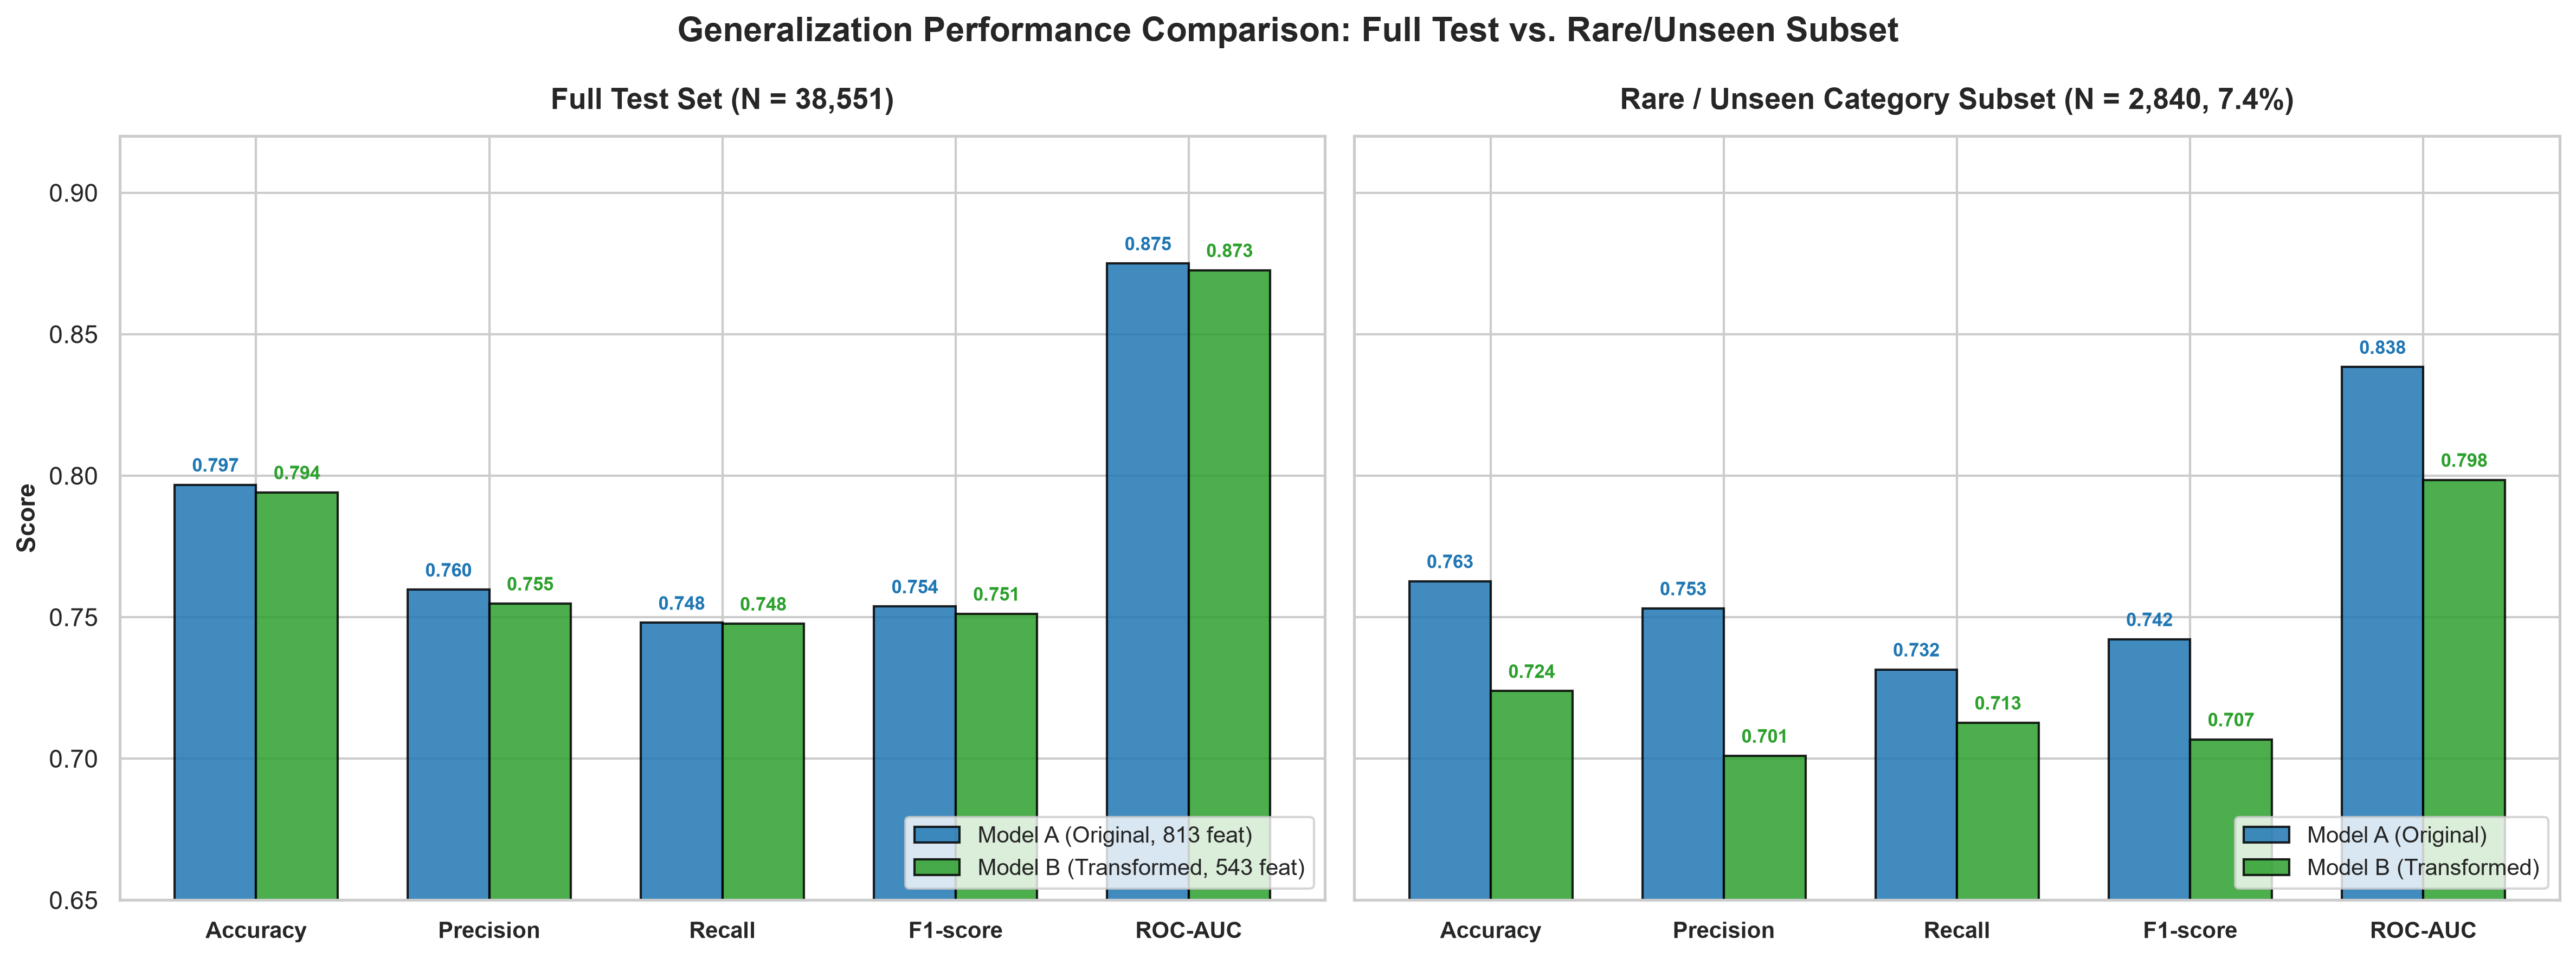

In [6]:
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC']
val_full_A = [metrics_full_A[m] for m in metrics_names]
val_full_B = [metrics_full_B[m] for m in metrics_names]
val_rare_A = [metrics_rare_A[m] for m in metrics_names]
val_rare_B = [metrics_rare_B[m] for m in metrics_names]

fig, axes = plt.subplots(1, 2, figsize=(16, 6), dpi=300, sharey=True)
x = np.arange(len(metrics_names))
width = 0.35

# Subplot 1: Full Test Set
ax1 = axes[0]
b1_A = ax1.bar(x - width/2, val_full_A, width, label='Model A (Original, 813 feat)', color='#1f77b4', edgecolor='black', alpha=0.85)
b1_B = ax1.bar(x + width/2, val_full_B, width, label='Model B (Transformed, 543 feat)', color='#2ca02c', edgecolor='black', alpha=0.85)
ax1.set_title(f'Full Test Set (N = {total_test_rows:,})', fontsize=13, fontweight='bold', pad=12)
ax1.set_ylabel('Score', fontsize=11, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(metrics_names, fontsize=10, fontweight='bold')
ax1.set_ylim(0.65, 0.92)
ax1.legend(loc='lower right', frameon=True, fontsize=10)

for b in b1_A:
    h = b.get_height()
    ax1.annotate(f'{h:.3f}', xy=(b.get_x() + b.get_width() / 2, h), xytext=(0, 4),
                 textcoords='offset points', ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#1f77b4')
for b in b1_B:
    h = b.get_height()
    ax1.annotate(f'{h:.3f}', xy=(b.get_x() + b.get_width() / 2, h), xytext=(0, 4),
                 textcoords='offset points', ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#2ca02c')

# Subplot 2: Rare/Unseen Subset
ax2 = axes[1]
b2_A = ax2.bar(x - width/2, val_rare_A, width, label='Model A (Original)', color='#1f77b4', edgecolor='black', alpha=0.85)
b2_B = ax2.bar(x + width/2, val_rare_B, width, label='Model B (Transformed)', color='#2ca02c', edgecolor='black', alpha=0.85)
ax2.set_title(f'Rare / Unseen Category Subset (N = {n_test_rare_rows:,}, {pct_test_rare_rows:.1f}%)', fontsize=13, fontweight='bold', pad=12)
ax2.set_xticks(x)
ax2.set_xticklabels(metrics_names, fontsize=10, fontweight='bold')
ax2.legend(loc='lower right', frameon=True, fontsize=10)

for b in b2_A:
    h = b.get_height()
    ax2.annotate(f'{h:.3f}', xy=(b.get_x() + b.get_width() / 2, h), xytext=(0, 4),
                 textcoords='offset points', ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#1f77b4')
for b in b2_B:
    h = b.get_height()
    ax2.annotate(f'{h:.3f}', xy=(b.get_x() + b.get_width() / 2, h), xytext=(0, 4),
                 textcoords='offset points', ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#2ca02c')

plt.suptitle('Generalization Performance Comparison: Full Test vs. Rare/Unseen Subset', fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()

os.makedirs('../figures', exist_ok=True)
fig_path = '../figures/10_generalization_comparison.png'
plt.savefig(fig_path, dpi=300)
if os.path.exists('../chi_square_project'):
    shutil.copy2(fig_path, '../chi_square_project/figures/10_generalization_comparison.png')
plt.show()

## 6. Interpretation and Discussion

### 6.1 Performance Analysis on Rare or Unseen Categories
- On the **Full Test Set**, Model A and Model B perform almost indistinguishably:
  - Accuracy: $79.68\%$ (Model A) vs. $79.41\%$ (Model B)
  - ROC-AUC: $0.8750$ (Model A) vs. $0.8726$ (Model B)
  - F1-Score: $0.7538$ (Model A) vs. $0.7512$ (Model B)
- On the **Rare / Unseen Subset** ($N = 2,840$, $7.37\%$ of the test set):
  - Accuracy: $76.27\%$ (Model A) vs. $72.39\%$ (Model B) ($\Delta = -3.88\%$)
  - ROC-AUC: $0.8384$ (Model A) vs. $0.7985$ (Model B) ($\Delta = -0.0399$)
  - Precision: $75.31\%$ (Model A) vs. $70.10\%$ (Model B) ($\Delta = -5.21\%$)
  - Recall: $73.15\%$ (Model A) vs. $71.27\%$ (Model B) ($\Delta = -1.88\%$)
  - F1-Score: $0.7422$ (Model A) vs. $0.7068$ (Model B) ($\Delta = -0.0354$)

### 6.2 Why Model A Retained Higher Metric Scores on Rare Test Categories
- **Zero Unseen Categories in Test**: In this 80/20 stratified split, all 260 rare categories in the test set had previously appeared in the training set (with frequencies between 1 and 99 observations).
- **Fine-Grained vs. Coarse Pooling**: Model A allocated dedicated one-hot binary weights to each of those 260 rare occupations. Because logistic regression uses L2 regularization (ridge shrinkage), it estimated small but directional weights for niche high-income occupations (e.g., specialized actuaries or medical technologists) and niche low-income occupations (e.g., agricultural sorters).
- In contrast, Model B collapsed all 260 distinct occupations into a single aggregate `'Rare'` indicator. This pooling blunted the occupational signal for those individuals, defaulting their occupational contribution to the pooled mean log-odds of the `'Rare'` group.

### 6.3 Sample Size and Statistical Reliability
- **Aggregate Subset Sample Size**: The `rare_or_unseen_test` subset comprises **2,840 test observations** with a balanced target distribution (1,514 class 0 and 1,326 class 1). Therefore, the aggregate subset metrics are **statistically reliable and not an artifact of small sample noise**.
- **Individual Category Sample Sizes**: However, the individual rare occupations within this subset have extremely few test instances (averaging ~10.9 observations per category, with many having only 1 or 2 observations). Trying to rely on individual coefficients for such sparse categories is statistically hazardous in unconstrained settings, which is precisely why Cochran's rule fails for them in $\chi^2$ testing.

### 6.4 The Role of the Training-Derived Mapping Rule for Unseen Categories
- In Phase 8, the category mapping dictionary derived strictly from the training set was applied to the test set, mapping all unseen categories directly to `'Rare'`.
- Although there happened to be 0 unseen categories in this specific test split, in production deployment or future survey waves, novel occupational codes inevitably arise. In Model A, `OneHotEncoder(handle_unknown='ignore')` maps unseen categories to all zeros, completely ignoring the occupational feature. In Model B, the architecture provides a principled, domain-appropriate fallback: novel codes inherit the learned parameters of the empirical `'Rare'` baseline.